## EDA – Recursos Humanos (AdventureWorks2025)

## 1. Configuración y conexión

In [126]:
# Si falta alguna librería, descomenta la línea:
%pip install pandas matplotlib seaborn pyodbc
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\ysmen\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB 1.3 MB/s eta 0:00:07
   ---------------------------------------- 0.0/8.3 MB 653.6 kB/s eta 0:00:13
   ---------------------------------------- 0.1/8.3 MB 465.5 kB/s eta 0:00:18
    --------------------------------------- 0.1/8.3 MB 595.3 kB/s eta 0:00:14
    --------------------------------------- 0.1/8.3 MB 514.3 kB/s eta 0:00:16
   - -------------------------------------- 0.2/8.3 MB 846.9 kB/s eta 0:00:10
   - -------------------------------------- 0.2/8.3 MB 846.9 kB/s eta 0:00:10
   - -------------------------------------- 0.4/8.3 MB 955.7 kB/s eta 0:00:09
   -- ------------------------------------- 0.5/8.3 MB 1.3 MB/s eta 0:00:07
   -- ------------------------------------- 0.6/8.3 MB 1.2 MB/s eta 0:00:07
   ---- ----------------------------------- 0.9/8.3 MB 1.8 MB/s eta 0:00:05
   ---- ----------------------------------- 1.0/8.3 MB 2.0 MB/s eta 0:00:04
   --


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\ysmen\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [109]:


import pyodbc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

SERVIDOR   = r".\SQLEXPRESS02"
BASE_DATOS = "AdventureWorks2025"
ESQUEMA    = "HumanResources"

try:
    conexion.close()
except Exception:
    pass

conexion = pyodbc.connect(
    "DRIVER={ODBC Driver 18 for SQL Server};"
    f"SERVER={SERVIDOR};"
    f"DATABASE={BASE_DATOS};"
    "Trusted_Connection=yes;"
    "TrustServerCertificate=yes;"
    "MARS_Connection=yes;"
)
print("¡Conexión exitosa!")

¡Conexión exitosa!


## 2. Inventario de tablas y estructura

In [110]:
tablas = consultar("""
    SELECT TABLE_NAME
    FROM INFORMATION_SCHEMA.TABLES
    WHERE TABLE_TYPE = 'BASE TABLE' AND TABLE_SCHEMA = ?
    ORDER BY TABLE_NAME;
""", [ESQUEMA])["TABLE_NAME"].tolist()

inventario = []
for t in tablas:
    n_filas = consultar(f"SELECT COUNT(*) AS n FROM [{ESQUEMA}].[{t}];").iloc[0, 0]
    n_cols = consultar("""
        SELECT COUNT(*) AS n
        FROM INFORMATION_SCHEMA.COLUMNS
        WHERE TABLE_SCHEMA = ? AND TABLE_NAME = ?;
    """, [ESQUEMA, t]).iloc[0, 0]
    inventario.append({"Tabla": t, "Registros": n_filas, "Columnas": n_cols})

display(pd.DataFrame(inventario))

,Tabla,Registros,Columnas
0,Department,16,4
1,Employee,290,16
2,EmployeeDepartmentHistory,296,6
3,EmployeePayHistory,316,5
4,JobCandidate,13,4
5,Shift,3,5


In [111]:
estructura = consultar("""
    SELECT c.TABLE_NAME  AS Tabla,
           c.COLUMN_NAME AS Columna,
           c.DATA_TYPE   AS Tipo,
           c.IS_NULLABLE AS Acepta_nulos
    FROM INFORMATION_SCHEMA.COLUMNS c
    JOIN INFORMATION_SCHEMA.TABLES t
      ON t.TABLE_SCHEMA = c.TABLE_SCHEMA AND t.TABLE_NAME = c.TABLE_NAME
    WHERE c.TABLE_SCHEMA = ? AND t.TABLE_TYPE = 'BASE TABLE'
    ORDER BY c.TABLE_NAME, c.ORDINAL_POSITION;
""", [ESQUEMA])

for tabla, grupo in estructura.groupby("Tabla"):
    print(f"\nESTRUCTURA DE: {ESQUEMA}.{tabla}")
    display(grupo.drop(columns="Tabla").reset_index(drop=True))


ESTRUCTURA DE: HumanResources.Department


,Columna,Tipo,Acepta_nulos
0,DepartmentID,smallint,NO
1,Name,nvarchar,NO
2,GroupName,nvarchar,NO
3,ModifiedDate,datetime,NO



ESTRUCTURA DE: HumanResources.Employee


,Columna,Tipo,Acepta_nulos
0,BusinessEntityID,int,NO
1,NationalIDNumber,nvarchar,NO
2,LoginID,nvarchar,NO
3,OrganizationNode,hierarchyid,YES
4,OrganizationLevel,smallint,YES
5,JobTitle,nvarchar,NO
6,BirthDate,date,NO
7,MaritalStatus,nchar,NO
8,Gender,nchar,NO
9,HireDate,date,NO



ESTRUCTURA DE: HumanResources.EmployeeDepartmentHistory


...

,Columna,Tipo,Acepta_nulos
0,BusinessEntityID,int,NO
1,RateChangeDate,datetime,NO
2,Rate,money,NO
3,PayFrequency,tinyint,NO
4,ModifiedDate,datetime,NO



ESTRUCTURA DE: HumanResources.JobCandidate


,Columna,Tipo,Acepta_nulos
0,JobCandidateID,int,NO
1,BusinessEntityID,int,YES
2,Resume,xml,YES
3,ModifiedDate,datetime,NO



ESTRUCTURA DE: HumanResources.Shift


,Columna,Tipo,Acepta_nulos
0,ShiftID,tinyint,NO
1,Name,nvarchar,NO
2,StartTime,time,NO
3,EndTime,time,NO
4,ModifiedDate,datetime,NO


## 3. Carga de datos


In [112]:
departamentos = consultar("""
    SELECT DepartmentID, Name AS Departamento, GroupName AS Grupo
    FROM HumanResources.Department;
""")

empleados = consultar("""
    SELECT BusinessEntityID,
           OrganizationNode.ToString() AS OrganizationNode,
           OrganizationLevel, JobTitle, BirthDate, MaritalStatus, Gender,
           HireDate, SalariedFlag, VacationHours, SickLeaveHours, CurrentFlag
    FROM HumanResources.Employee;
""")

hist_dep = consultar("""
    SELECT BusinessEntityID, DepartmentID, ShiftID, StartDate, EndDate
    FROM HumanResources.EmployeeDepartmentHistory;
""")

turnos = consultar("""
    SELECT ShiftID, Name AS Turno,
           CAST(StartTime AS VARCHAR(8)) AS Inicio,
           CAST(EndTime   AS VARCHAR(8)) AS Fin
    FROM HumanResources.Shift;
""")

pagos = consultar("""
    SELECT BusinessEntityID, RateChangeDate,
           CAST(Rate AS FLOAT) AS Rate, PayFrequency
    FROM HumanResources.EmployeePayHistory;
""")

candidatos = consultar("""
    SELECT JobCandidateID, BusinessEntityID, ModifiedDate,
           CASE WHEN Resume IS NULL THEN 0 ELSE 1 END AS TieneResume
    FROM HumanResources.JobCandidate;
""")

tablas_df = {
    "Department": departamentos,
    "Employee": empleados,
    "EmployeeDepartmentHistory": hist_dep,
    "EmployeePayHistory": pagos,
    "JobCandidate": candidatos,
    "Shift": turnos,
}
for nombre, df in tablas_df.items():
    print(f"{nombre:<28} {df.shape}")

display(empleados.head())

Department                   (16, 3)
Employee                     (290, 12)
EmployeeDepartmentHistory    (296, 5)
EmployeePayHistory           (316, 4)
JobCandidate                 (13, 4)
Shift                        (3, 4)


,BusinessEntityID,OrganizationNode,OrganizationLevel,JobTitle,BirthDate,MaritalStatus,Gender,HireDate,SalariedFlag,VacationHours,SickLeaveHours,CurrentFlag
0,1,NaN,NaN,Chief Executive Officer,1969-01-29,S,M,2009-01-14,True,99,69,True
1,2,/1/,1.00,Gerente,1971-08-01,S,F,2008-01-31,True,1,20,True
2,3,/1/1/,2.00,Engineering Manager,1974-11-12,M,M,2007-11-11,True,2,21,True
3,4,/1/1/1/,3.00,Senior Tool Designer,1974-12-23,S,M,2007-12-05,False,48,80,True
4,5,/1/1/2/,3.00,Design Engineer,1952-09-27,M,F,2008-01-06,True,5,22,True


## 4. Calidad de datos
Revisión de nulos y duplicados antes de analizar.

In [113]:
resumen = pd.DataFrame({
    nombre: {
        "Filas": len(df),
        "Columnas": df.shape[1],
        "Nulos": int(df.isnull().sum().sum()),
        "Duplicados": int(df.duplicated().sum()),
    }
    for nombre, df in tablas_df.items()
}).T
display(resumen)

print("Columnas con valores nulos:")
for nombre, df in tablas_df.items():
    nulos = df.isnull().sum()
    nulos = nulos[nulos > 0]
    if not nulos.empty:
        print(f"\n{nombre}")
        display(nulos.to_frame("Nulos").assign(Porcentaje=(nulos / len(df) * 100).round(1)))

,Filas,Columnas,Nulos,Duplicados
Department,16,3,0,0
Employee,290,12,2,0
EmployeeDepartmentHistory,296,5,290,0
EmployeePayHistory,316,4,0,0
JobCandidate,13,4,11,0
Shift,3,4,0,0


Columnas con valores nulos:

Employee


,Nulos,Porcentaje
OrganizationNode,1,0.30
OrganizationLevel,1,0.30



EmployeeDepartmentHistory


,Nulos,Porcentaje
EndDate,290,98.00



JobCandidate


,Nulos,Porcentaje
BusinessEntityID,11,84.60


## 5. Limpieza 

In [114]:
# --- Fechas
for col in ["BirthDate", "HireDate"]:
    empleados[col] = pd.to_datetime(empleados[col])
for col in ["StartDate", "EndDate"]:
    hist_dep[col] = pd.to_datetime(hist_dep[col])
pagos["RateChangeDate"] = pd.to_datetime(pagos["RateChangeDate"])

# --- Etiquetas legibles
empleados["Genero"]      = empleados["Gender"].map({"M": "Masculino", "F": "Femenino"})
empleados["EstadoCivil"] = empleados["MaritalStatus"].map({"M": "Casado", "S": "Soltero"})
empleados["TipoPago"]    = empleados["SalariedFlag"].map({True: "Asalariado", False: "Por hora"})
empleados["Estado"]      = empleados["CurrentFlag"].map({True: "Activo", False: "Inactivo"})
pagos["Frecuencia"]      = pagos["PayFrequency"].map({1: "Mensual", 2: "Quincenal"})

# --- Variables derivadas
FECHA_CORTE = empleados["HireDate"].max()
empleados["AnioContratacion"] = empleados["HireDate"].dt.year
empleados["EdadContratacion"] = (empleados["HireDate"] - empleados["BirthDate"]).dt.days / 365.25
empleados["AntiguedadAnios"]  = (FECHA_CORTE - empleados["HireDate"]).dt.days / 365.25

print("Fecha de corte:", FECHA_CORTE.date())
display(empleados[["HireDate", "EdadContratacion", "AntiguedadAnios", "Genero", "TipoPago"]].head())

Fecha de corte: 2013-05-30


,HireDate,EdadContratacion,AntiguedadAnios,Genero,TipoPago
0,2009-01-14,39.96,4.37,Masculino,Asalariado
1,2008-01-31,36.50,5.33,Femenino,Asalariado
2,2007-11-11,33.00,5.55,Masculino,Asalariado
3,2007-12-05,32.95,5.48,Masculino,Por hora
4,2008-01-06,55.27,5.40,Femenino,Asalariado


## 6. Análisis de empleados (univariado)

### 6.1 Variables categóricas

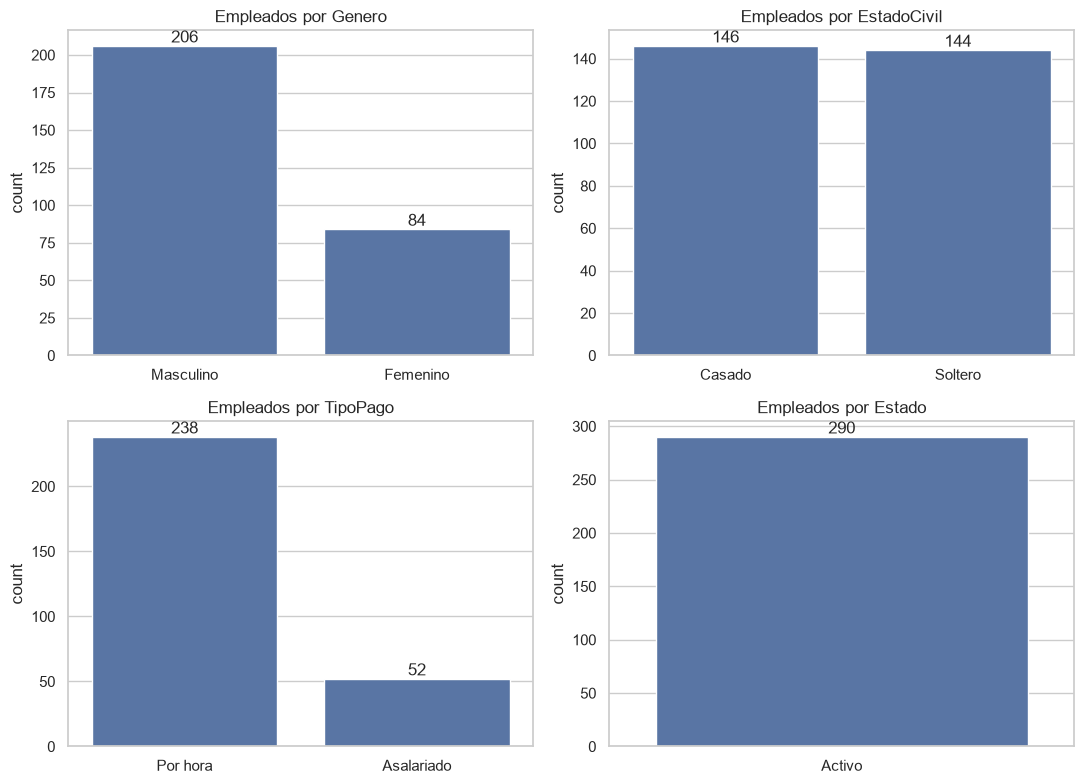


Genero (%)
Genero
Masculino   71.00
Femenino    29.00

EstadoCivil (%)
EstadoCivil
Casado    50.30
Soltero   49.70

TipoPago (%)
TipoPago
Por hora     82.10
Asalariado   17.90

Estado (%)
Estado
Activo   100.00


In [115]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), ["Genero", "EstadoCivil", "TipoPago", "Estado"]):
    sns.countplot(data=empleados, x=col, order=empleados[col].value_counts().index, ax=ax)
    ax.set_title(f"Empleados por {col}")
    ax.set_xlabel("")
    for c in ax.containers:
        ax.bar_label(c)
plt.tight_layout()
plt.show()

# Mismas cifras en porcentaje
for col in ["Genero", "EstadoCivil", "TipoPago", "Estado"]:
    print(f"\n{col} (%)")
    print((empleados[col].value_counts(normalize=True) * 100).round(1).to_string())

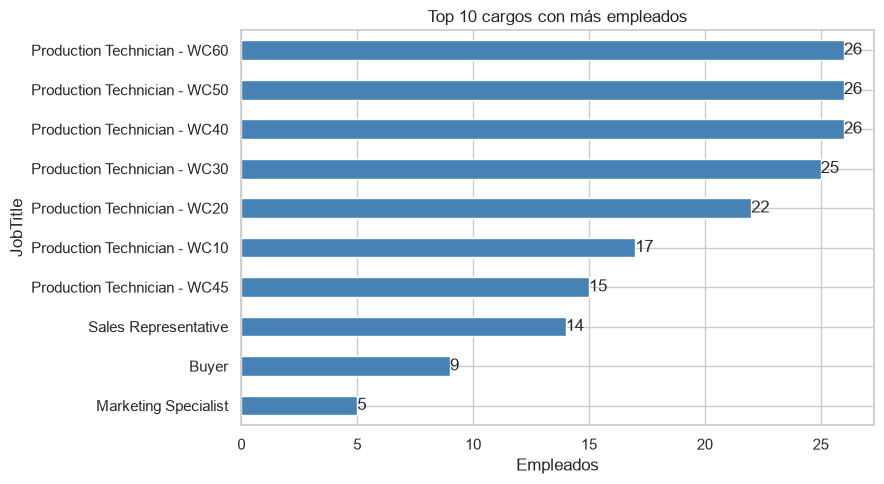

Cargos distintos: 67


In [116]:
top_cargos = empleados["JobTitle"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
top_cargos.plot.barh(ax=ax, color="steelblue")
ax.set_title("Top 10 cargos con más empleados")
ax.set_xlabel("Empleados")
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

print("Cargos distintos:", empleados["JobTitle"].nunique())

### 6.2 Variables numéricas

,count,mean,std,min,25%,50%,75%,max
VacationHours,290.00,50.61,28.79,0.00,26.25,51.00,75.00,99.00
SickLeaveHours,290.00,45.31,14.54,20.00,33.00,46.00,58.00,80.00
EdadContratacion,290.00,30.87,9.43,17.64,23.15,30.61,36.48,59.22
AntiguedadAnios,290.00,4.03,0.92,0.00,3.64,4.32,4.42,6.92


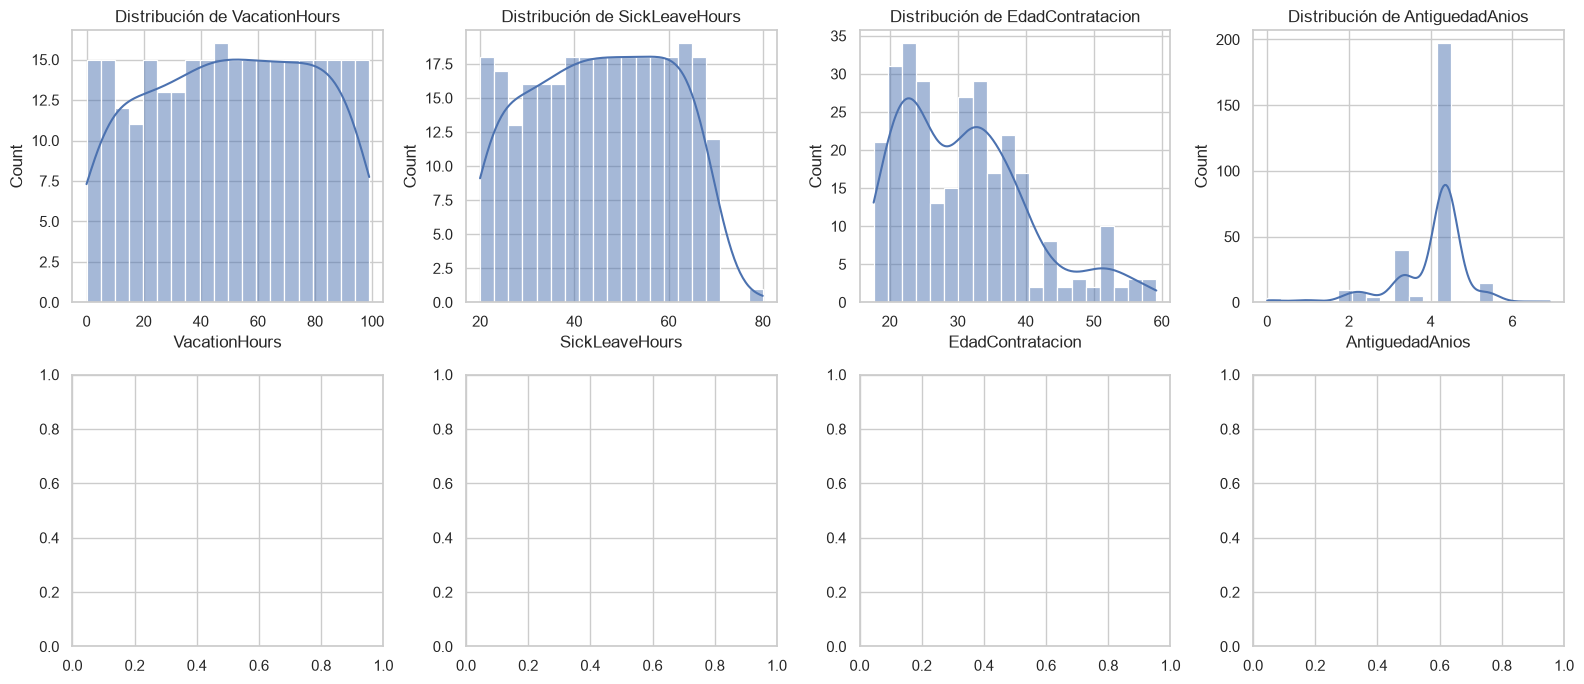

In [117]:
numericas = ["VacationHours", "SickLeaveHours", "EdadContratacion", "AntiguedadAnios"]
display(empleados[numericas].describe().T)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, col in enumerate(numericas):
    sns.histplot(empleados[col], bins=20, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

### 6.3 Contrataciones en el tiempo

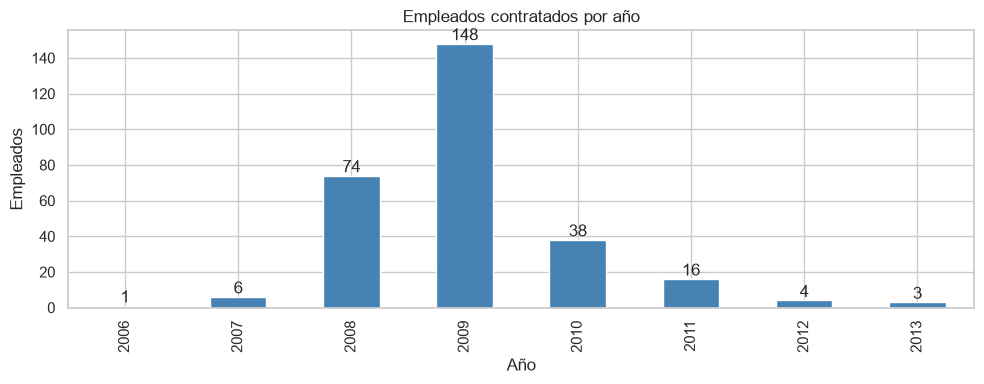

In [118]:
contrataciones = empleados.groupby("AnioContratacion").size()

fig, ax = plt.subplots(figsize=(10, 4))
contrataciones.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Empleados contratados por año")
ax.set_xlabel("Año")
ax.set_ylabel("Empleados")
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

## 7. Departamentos y turnos

In [119]:
actual = (
    hist_dep[hist_dep["EndDate"].isna()]
    .merge(departamentos, on="DepartmentID", how="left")
    .merge(turnos, on="ShiftID", how="left")
)

print("Asignaciones vigentes:", len(actual))
print("Empleados con más de una asignación vigente:", actual["BusinessEntityID"].duplicated().sum())

# Cuántos departamentos ha tenido cada empleado
cambios = hist_dep.groupby("BusinessEntityID").size().value_counts().sort_index()
print("\nEmpleados según número de asignaciones históricas:")
print(cambios.to_string())

Asignaciones vigentes: 290
Empleados con más de una asignación vigente: 0

Empleados según número de asignaciones históricas:
1    285
2      4
3      1


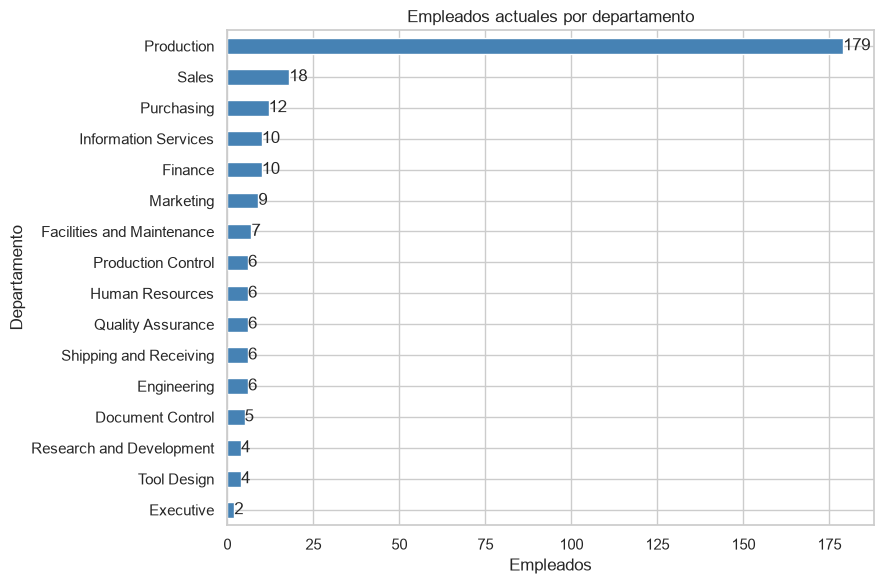

In [120]:
por_depto = actual["Departamento"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
por_depto.plot.barh(ax=ax, color="steelblue")
ax.set_title("Empleados actuales por departamento")
ax.set_xlabel("Empleados")
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()


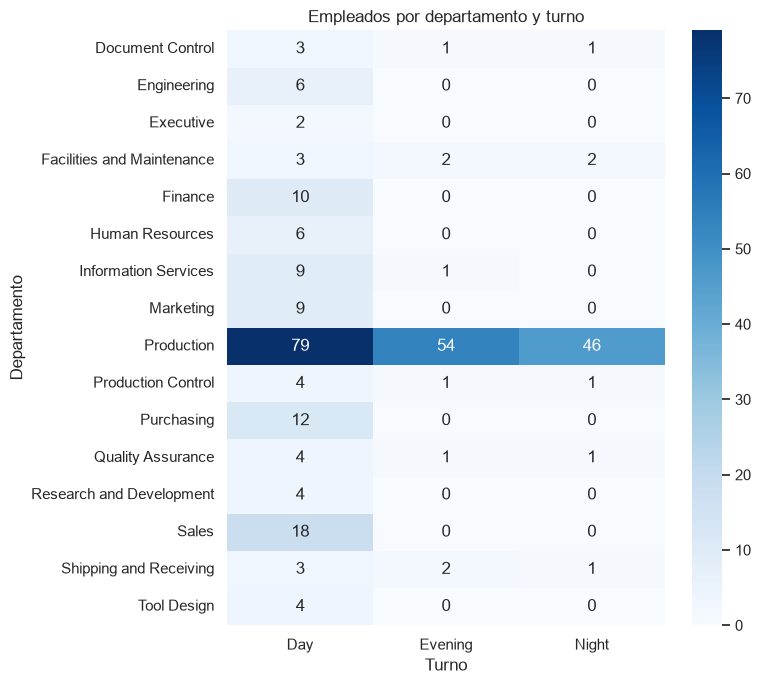

In [ ]:
tabla_cruzada = pd.crosstab(actual["Departamento"], actual["Turno"])

plt.figure(figsize=(8, 7))
sns.heatmap(tabla_cruzada, annot=True, fmt="d", cmap="Blues")
plt.title("Empleados por departamento y turno")
plt.tight_layout()
plt.show()

## 8. Historial de pagos

,count,mean,std,min,25%,50%,75%,max
Rate,316.00,17.76,12.28,6.50,11.00,14.00,23.08,125.50



Cambios de tarifa por empleado:
1    277
3     13


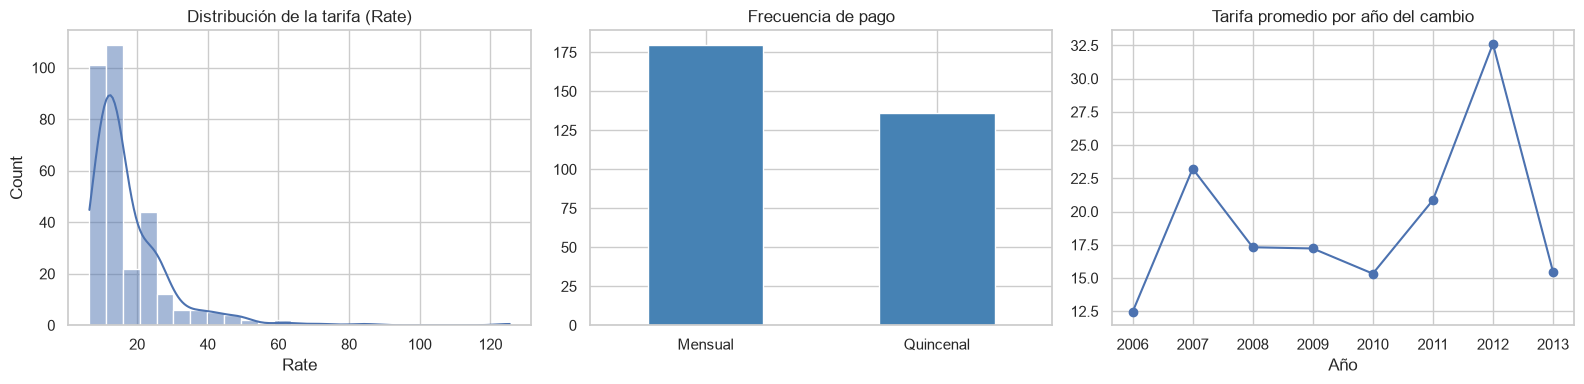

In [122]:
display(pagos["Rate"].describe().to_frame().T)
print("\nCambios de tarifa por empleado:")
print(pagos.groupby("BusinessEntityID").size().value_counts().sort_index().to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(pagos["Rate"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Distribución de la tarifa (Rate)")

pagos["Frecuencia"].value_counts().plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title("Frecuencia de pago")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)

pagos.groupby(pagos["RateChangeDate"].dt.year)["Rate"].mean().plot(marker="o", ax=axes[2])
axes[2].set_title("Tarifa promedio por año del cambio")
axes[2].set_xlabel("Año")
plt.tight_layout()
plt.show()

In [123]:
# Tarifa vigente = último cambio registrado de cada empleado
ultimo_pago = (
    pagos.sort_values("RateChangeDate")
    .groupby("BusinessEntityID", as_index=False)
    .tail(1)[["BusinessEntityID", "Rate", "Frecuencia"]]
    .rename(columns={"Rate": "TarifaActual"})
)
print("Empleados con tarifa vigente:", len(ultimo_pago))
display(ultimo_pago["TarifaActual"].describe().to_frame().T)

Empleados con tarifa vigente: 290


,count,mean,std,min,25%,50%,75%,max
TarifaActual,290.00,18.19,12.29,9.00,11.00,14.00,23.08,125.50


In [131]:
base = (
    empleados
    .merge(actual[["BusinessEntityID", "Departamento", "Grupo", "Turno"]], on="BusinessEntityID", how="left")
    .merge(ultimo_pago, on="BusinessEntityID", how="left")
)
print("Tabla consolidada:", base.shape)
display(base.head())

Tabla consolidada: (290, 24)


,BusinessEntityID,OrganizationNode,OrganizationLevel,JobTitle,BirthDate,MaritalStatus,Gender,HireDate,SalariedFlag,VacationHours,SickLeaveHours,CurrentFlag,Genero,EstadoCivil,TipoPago,Estado,AnioContratacion,EdadContratacion,AntiguedadAnios,Departamento,Grupo,Turno,TarifaActual,Frecuencia
0,1,NaN,NaN,Chief Executive Officer,1969-01-29,S,M,2009-01-14,True,99,69,True,Masculino,Soltero,Asalariado,Activo,2009,39.96,4.37,Executive,Executive General and Administration,Day,125.50,Quincenal
1,2,/1/,1.00,Gerente,1971-08-01,S,F,2008-01-31,True,1,20,True,Femenino,Soltero,Asalariado,Activo,2008,36.50,5.33,Engineering,Research and Development,Day,63.46,Quincenal
2,3,/1/1/,2.00,Engineering Manager,1974-11-12,M,M,2007-11-11,True,2,21,True,Masculino,Casado,Asalariado,Activo,2007,33.00,5.55,Engineering,Research and Development,Day,43.27,Quincenal
3,4,/1/1/1/,3.00,Senior Tool Designer,1974-12-23,S,M,2007-12-05,False,48,80,True,Masculino,Soltero,Por hora,Activo,2007,32.95,5.48,Tool Design,Research and Development,Day,29.85,Quincenal
4,5,/1/1/2/,3.00,Design Engineer,1952-09-27,M,F,2008-01-06,True,5,22,True,Femenino,Casado,Asalariado,Activo,2008,55.27,5.40,Engineering,Research and Development,Day,32.69,Quincenal


## 9. Segmentación de empleados (clustering K-Means)



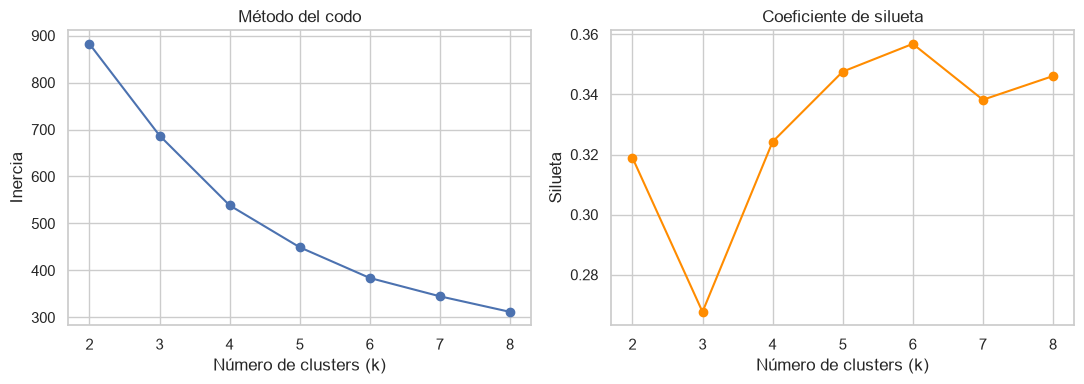

k con mayor silueta: 6


In [130]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

variables = ["EdadContratacion", "AntiguedadAnios", "TarifaActual", "VacationHours"]

datos = base[variables].copy()
datos["TarifaActual"] = np.log1p(datos["TarifaActual"])
X = StandardScaler().fit_transform(datos)

ks = range(2, 9)
inercia, silueta = [], []
for k in ks:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inercia.append(modelo.inertia_)
    silueta.append(silhouette_score(X, modelo.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inercia, marker="o")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inercia")
axes[1].plot(ks, silueta, marker="o", color="darkorange")
axes[1].set_title("Coeficiente de silueta")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silueta")
plt.tight_layout()
plt.show()

print("k con mayor silueta:", list(ks)[int(np.argmax(silueta))])

,Empleados,Edad_contratacion,Antiguedad,Tarifa_media,Tarifa_mediana,Horas_vacaciones
Cluster,,,,,,
0,52,27.92,4.43,33.30,26.44,60.21
1,39,38.91,2.24,23.21,23.08,24.36
2,41,45.07,4.20,17.38,15.00,65.07
3,58,26.15,4.12,11.71,11.00,86.14
4,100,26.19,4.39,12.46,12.45,29.33



% por tipo de pago dentro de cada cluster


TipoPago,Asalariado,Por hora
Cluster,,
0,50.00,50.00
1,53.80,46.20
2,9.80,90.20
3,1.70,98.30
4,0.00,100.00



% por grupo de departamentos dentro de cada cluster


Grupo,Executive General and Administration,Inventory Management,Manufacturing,Quality Assurance,Research and Development,Sales and Marketing
Cluster,,,,,,
0,42.30,1.90,36.50,3.80,13.50,1.90
1,0.00,7.70,28.20,0.00,10.30,53.80
2,7.30,22.00,58.50,2.40,7.30,2.40
3,8.60,8.60,69.00,13.80,0.00,0.00
4,5.00,0.00,91.00,0.00,0.00,4.00


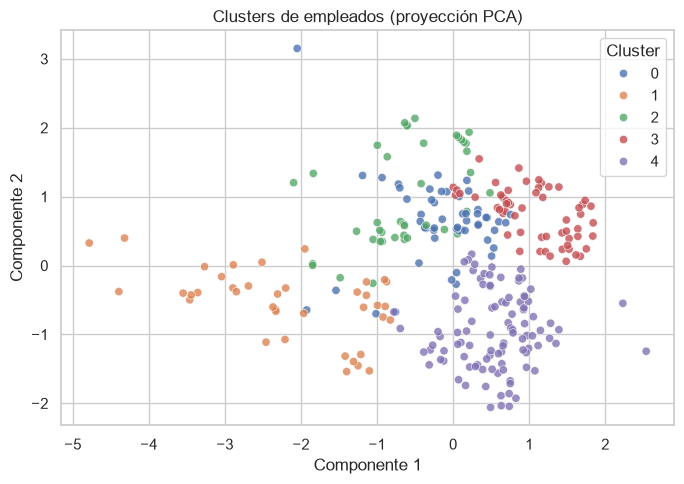

In [129]:
K = 5  

modelo = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
base["Cluster"] = modelo.labels_

perfil = base.groupby("Cluster").agg(
    Empleados=("BusinessEntityID", "count"),
    Edad_contratacion=("EdadContratacion", "mean"),
    Antiguedad=("AntiguedadAnios", "mean"),
    Tarifa_media=("TarifaActual", "mean"),
    Tarifa_mediana=("TarifaActual", "median"),
    Horas_vacaciones=("VacationHours", "mean"),
).round(2)
display(perfil)

print("\n% por tipo de pago dentro de cada cluster")
display((pd.crosstab(base["Cluster"], base["TipoPago"], normalize="index") * 100).round(1))
print("\n% por grupo de departamentos dentro de cada cluster")
display((pd.crosstab(base["Cluster"], base["Grupo"], normalize="index") * 100).round(1))

componentes = PCA(n_components=2, random_state=42).fit_transform(X)
plt.figure(figsize=(7, 5))
sns.scatterplot(x=componentes[:, 0], y=componentes[:, 1], hue=base["Cluster"], palette="deep", alpha=0.8)
plt.title("Clusters de empleados (proyección PCA)")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.tight_layout()
plt.show()

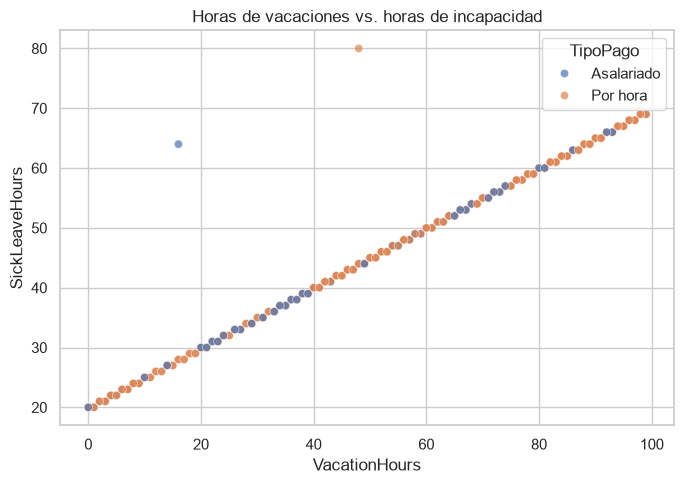

Promedio de horas por tipo de pago:


,VacationHours,SickLeaveHours
TipoPago,,
Asalariado,44.00,42.44
Por hora,52.06,45.93


In [ ]:
# Correlaciones entre variables numéricas
cols_corr = ["VacationHours", "SickLeaveHours", "EdadContratacion", "AntiguedadAnios", "TarifaActual"]

plt.figure(figsize=(7, 5))
sns.scatterplot(data=base, x="VacationHours", y="SickLeaveHours", hue="TipoPago", alpha=0.7)
plt.title("Horas de vacaciones vs. horas de incapacidad")
plt.tight_layout()
plt.show()

print("Promedio de horas por tipo de pago:")
display(base.groupby("TipoPago")[["VacationHours", "SickLeaveHours"]].mean())

## 10. Candidatos (JobCandidate)

In [ ]:
candidatos["Resultado"] = np.where(candidatos["BusinessEntityID"].notna(), "Contratado", "No contratado")

print("Total de candidatos:", len(candidatos))
print("Con hoja de vida registrada:", int(candidatos["TieneResume"].sum()))
display(candidatos["Resultado"].value_counts().to_frame("Candidatos"))

Total de candidatos: 13
Con hoja de vida registrada: 13


,Candidatos
Resultado,
No contratado,11
Contratado,2


## 11. Conclusiones

1. **Plantilla:** la base tiene 290 empleados activos, 16 departamentos y 3 turnos. El 71% son hombres, el 82% cobra por hora y el cargo más frecuente es Production Technician.
2. **Calidad de datos:** no hay duplicados ni llaves huérfanas. Los nulos son esperables: OrganizationNode/OrganizationLevel en el CEO (raíz del organigrama), EndDate en las 290 asignaciones vigentes y BusinessEntityID en los 11 candidatos no contratados. No hay atípicos en horas de vacaciones ni de incapacidad; los atípicos en edad (4) y antigüedad (28) reflejan contrataciones fuera de la ola principal.
3. **Estructura organizacional:** Production concentra 179 empleados (62%) y el grupo Manufacturing es el más grande. Solo 5 empleados han cambiado de departamento. Los turnos de tarde y noche son casi exclusivos de Production.
4. **Contratación:** el 77% de la plantilla se contrató entre 2008 y 2009 (148 personas solo en 2009), lo que explica el pico de antigüedad en torno a 4,3 años.
6. **Relaciones:** horas de vacaciones y de incapacidad están casi perfectamente correlacionadas (r = 0,98), lo que sugiere datos generados con una regla y no un comportamiento real. El resto de correlaciones es débil (|r| < 0,26); la más relevante es edad al contratar vs. antigüedad (−0,25).
7. **Segmentación (K-Means, k = 5):** se identificaron cinco perfiles: administrativos y técnicos de tarifa alta (52), ventas y marketing de contratación reciente (39), operativos de mayor edad (41), operativos jóvenes con muchas horas de vacaciones (58) y producción joven por hora (100). Los grupos son moderadamente separables (silueta ≈ 0,35) y la separación entre los dos últimos depende sobre todo de las horas de vacaciones.
8. **Candidatos:** de 13 candidatos solo 2 (15%) fueron contratados.

In [ ]:
conexion.close()
print("Conexión cerrada.")

Conexión cerrada.
